<a href="https://colab.research.google.com/github/HannaSkrypnyk/DTA-Python-26/blob/main/Hanna_%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D0%B0_%D0%B8%CC%86%D0%BC%D0%BE%D0%B2%D1%96%D1%80%D0%BD%D1%96%D1%81%D1%82%D1%8C_%D0%BA%D0%BE%D1%80%D0%B5%D0%BB%D1%8F%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✍️ Практика: ймовірність, вибірки та кореляція

**Самостійна робота · 36 завдань**

Сьогодні три набори даних:
- `students` — 800 студентів онлайн-школи «ВчиОнлайн»;
- `app` — усі 50 000 користувачів мобільного застосунку (наша «генеральна сукупність»);
- `city` — щоденні дані міста за 2 роки: опади, продажі парасольок, ДТП.

| Блок | Тема | Час |
|---|---|---|
| 1 | Базові поняття ймовірності | 30 хв |
| 2 | Генеральна сукупність і вибірка | 25 хв |
| 3 | Закон великих чисел | 20 хв |
| 4 | Центральна гранична теорема | 30 хв |
| 5 | Діаграма розсіювання і коваріація | 25 хв |
| 6 | Коефіцієнт кореляції Пірсона | 30 хв |
| 7 | Кореляція ≠ причинність | 20 хв |
| 8 | Підсумковий міні-звіт | 15 хв |

---

### Як працювати з цим блокнотом

1. **Запускайте клітинки по черзі зверху вниз** (Shift + Enter). Спочатку обов'язково запустіть три службові клітинки в розділі «Підготовка».
2. **Пропуски `ВАШ_КОД`** у коді треба замінити на правильний код. Поки пропуск не заповнено, клітинка видасть помилку на кшталт `NameError: name 'ВАШ_КОД' is not defined`, і це нормально.
3. **Підказки відкриваються кліком** на «💡 Підказка 1». Спершу спробуйте самі, потім відкрийте першу підказку. Друга підказка майже містить відповідь, тож користуйтеся нею, якщо зовсім застрягли.
4. **Самоперевірка:** після більшості завдань є клітинка з `check(...)`. Запустіть її, і вона напише ✅ або ❌.
5. **Текстові відповіді:** клітинки «✍️ Ваша відповідь» двічі клацніть і напишіть відповідь своїми словами.
6. Завдання з ⭐ — **бонусні**. Якщо часу мало, їх можна пропустити.
7. Застрягли на завданні більше ніж на 10 хвилин — переходьте до наступного і поверніться пізніше.

> 💡 Відкрити в Google Colab: *File → Upload notebook*. Усі дані генеруються всередині блокнота.

---
## Підготовка

Запустіть три клітинки нижче: бібліотеки, дані та функції самоперевірки.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from itertools import product
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.float_format', '{:.3f}'.format)

### Дані

**`students`** — студенти онлайн-школи (опис колонок — у блоці 5).

**`app`** — користувачі застосунку: `user_id`, `platform` (iOS / Android / Web), `session_min` — середня тривалість сесії, хв.

**`city`** — дні: `rain_mm` — опади, мм; `umbrellas` — продано парасольок; `accidents` — кількість ДТП.

In [2]:
rng = np.random.default_rng(2027)

# --- 1. Студенти онлайн-школи «ВчиОнлайн» (блоки 1, 5–8) ---
n = 800
motivation = rng.normal(0, 1, n)                     # прихована мотивація: її в таблиці немає
hours = np.clip(22 + 7 * motivation + rng.normal(0, 6, n), 1, None)
tasks = np.clip(np.round(14 + 4 * motivation + 0.15 * hours + rng.normal(0, 3, n)), 0, 40)
score = np.clip(30 + 0.9 * hours + 0.8 * tasks + rng.normal(0, 8, n), 0, 100)
load = rng.uniform(2, 20, n)

students = pd.DataFrame({
    'student_id':      np.arange(1, n + 1),
    'plan':            np.where(motivation + rng.normal(0, 0.8, n) > 0.7, 'Преміум', 'Базовий'),
    'age':             np.round(np.clip(rng.normal(29, 6, n), 18, 55)).astype(int),
    'hours_watched':   hours.round(1),
    'tasks_done':      tasks.astype(int),
    'forum_posts':     rng.poisson(np.exp(1.0 + 0.45 * motivation)),
    'support_tickets': rng.poisson(np.clip(2.2 - 0.7 * motivation, 0.1, None)),
    'weekly_load_h':   load.round(1),
    'satisfaction':    np.clip(9 - 0.06 * (load - 11) ** 2 + rng.normal(0, 0.7, n), 1, 10).round(1),
    'final_score':     score.round(1),
})
students['passed'] = students['final_score'] >= 60

# --- 2. «Генеральна сукупність»: 50 000 користувачів мобільного застосунку (блоки 2–4) ---
N = 50_000
platform = rng.choice(['iOS', 'Android', 'Web'], size=N, p=[0.35, 0.50, 0.15])
mult = pd.Series(platform).map({'iOS': 1.3, 'Android': 1.0, 'Web': 0.6}).to_numpy()
app = pd.DataFrame({
    'user_id':     np.arange(1, N + 1),
    'platform':    platform,
    'session_min': np.round(rng.gamma(1.5, 8, N) * mult, 1),
})

# --- 3. Щоденні дані міста за 2 роки (блок 7) ---
days = 730
rain = np.where(rng.random(days) < 0.55, 0.0, np.round(rng.gamma(0.9, 7, days), 1))
city = pd.DataFrame({
    'rain_mm':    rain,
    'umbrellas':  np.round(20 + 6 * rain + rng.normal(0, 8, days)).clip(0).astype(int),
    'accidents':  rng.poisson(3 + 0.25 * rain),
})

print('students:', students.shape, '| app:', app.shape, '| city:', city.shape)

students: (800, 11) | app: (50000, 3) | city: (730, 3)


In [ ]:
# ⚙️ Службова клітинка: функції для самоперевірки. Просто запустіть її, змінювати нічого не потрібно.
ANSWERS = {
    '1.1': [0.111111, 0.25],
    '1.2': [0.166667],
    '1.3': [0.166667],
    '1.4': [0.862552],
    '1.5': [0.9702, 0.0298],
    '1.6': [0.625, 0.1975],
    '1.7': [0.876543, 0.51526],
    '2.1': [12.510538],
    '2.2': [13.602],
    '2.3': [7.1206],
    '2.4': [2.319551, 0.741077, 0.228901],
    '3.1': [0.3, 0.56, 0.507],
    '3.3': [0.4105, 0.009],
    '3.4': [3.5],
    '4.1': [1.799823],
    '4.2': [12.497931, 1.705579],
    '4.3': [1.698323],
    '4.4': [1.337772, 0.237511],
    '4.5': [462.0],
    '5.3': [108.5],
    '5.4': [115.379778, 6922.786708],
    '6.1': [0.821934],
    '6.2': [0.821934],
    '6.3': ['hours_watched', 'age'],
    '6.5': [-0.029193],
    '6.6': [-0.015113, 0.898861],
    '7.1': [0.556014],
    '7.2': [-0.02991],
    '7.3': [14.443661],
    '7.4': [3.382355],
}
TOL = {'1.3': 0.01, '3.4': 0.05}

def check(task, *values):
    expected = ANSWERS[task]
    if len(values) != len(expected):
        print(f'⚠️ Очікую {len(expected)} значення(нь), а отримала функція {len(values)}.')
        return
    ok = True
    for v, e in zip(values, expected):
        if isinstance(e, str):
            good = str(v).strip().lower() == e.lower()
        else:
            try:
                tol = TOL.get(task, max(0.01, abs(e) * 0.005))
                good = abs(float(v) - e) <= tol
            except (TypeError, ValueError):
                good = False
        ok = ok and good
    if ok:
        print(f'✅ Завдання {task}: правильно! Можна рухатися далі.')
    else:
        print(f'❌ Завдання {task}: поки не збігається. Перевірте код і відкрийте підказку.')

---

## Блок 1. Базові поняття ймовірності

**Нагадування:**

| Що | Формула |
|---|---|
| Класична ймовірність | P(A) = сприятливі результати ÷ усі результати |
| Частотна ймовірність | P(A) ≈ скільки разів сталося A ÷ кількість спроб |
| Доповнення | P(не A) = 1 − P(A) |
| Множення (незалежні події) | P(A і B) = P(A) · P(B) |
| «Хоча б один» з n незалежних спроб | 1 − (1 − p)ⁿ |

**Корисний трюк:** частка True у колонці з True/False = `.mean()` цієї колонки.

### Завдання 1.1. Колода карт

У колоді 36 карт: 4 масті по 9 карт, серед них 4 тузи (по одному в кожній масті). Знайдіть ймовірність витягнути навмання **туза** і ймовірність витягнути карту **червової масті**. Збережіть у `p_ace` і `p_heart`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Класична ймовірність: кількість «сприятливих» карт ÷ кількість усіх карт. Скільки карт однієї масті?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
p_ace = 4 / 36
p_heart = 9 / 36
```

</details>

In [3]:
total = 36
aces = 4
hearts = 9

p_ace = aces / total
p_heart = hearts / total
print(f'P(туз) = {p_ace:.3f} | P(черва) = {p_heart:.3f}')

P(туз) = 0.111 | P(черва) = 0.250


In [5]:
check('1.1', p_ace, p_heart)

NameError: name 'check' is not defined

### Завдання 1.2. Сума двох кубиків ≥ 10 (перебором)

Кидаємо два кубики. Перебравши всі 36 комбінацій, знайдіть ймовірність, що сума буде **не менше 10**. Збережіть у `p_ge10`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`product(range(1, 7), repeat=2)` дає всі пари (1,1), (1,2), …, (6,6). Залиште лише ті пари, де `sum(pair) >= 10`, і поділіть їх кількість на кількість усіх пар.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
all_pairs = list(product(range(1, 7), repeat=2))
good = [pair for pair in all_pairs if sum(pair) >= 10]
p_ge10 = len(good) / len(all_pairs)
```

Для самоперевірки: таких пар 6 — (4,6), (5,5), (5,6), (6,4), (6,5), (6,6).

</details>

In [4]:
all_pairs = list(product(range(1, 7), repeat=2))
good = [pair for pair in all_pairs if sum(pair) >= 10]

print('Сприятливі пари:', good)
p_ge10 = len(good) / len(all_pairs)
print(f'P(сума ≥ 10) = {p_ge10:.3f}')

Сприятливі пари: [(4, 6), (5, 5), (5, 6), (6, 4), (6, 5), (6, 6)]
P(сума ≥ 10) = 0.167


In [ ]:
check('1.2', p_ge10)

### Завдання 1.3. Те саме симуляцією

Змоделюйте 100 000 кидків двох кубиків і порахуйте **частку** кидків, де сума ≥ 10. Збережіть у `p_sim` і порівняйте з `p_ge10`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`gen.integers(1, 7, size=(100_000, 2))` дає таблицю: 100 000 рядків (кидків) і 2 колонки (кубики). Суму в кожному рядку рахує `.sum(axis=1)` — `axis=1` означає «додавати вздовж рядка».

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
sums = rolls.sum(axis=1)
p_sim = (sums >= 10).mean()
```

</details>

In [6]:
gen = np.random.default_rng(10)
rolls = gen.integers(1, 7, size=(100_000, 2))

sums = rolls.sum(axis=1)
p_sim = (sums >= 10).mean()
print(f'Симуляція: {p_sim:.4f} | Теорія: {p_ge10:.4f}')

Симуляція: 0.1656 | Теорія: 0.1667


In [ ]:
check('1.3', p_sim)

### Завдання 1.4. Розсилка: хоча б один відкриє

Ймовірність, що клієнт відкриє лист, дорівнює 0.18. Надіслали 10 листів різним клієнтам (вони діють незалежно). Яка ймовірність, що **хоча б один** відкриє лист? Збережіть у `p_open`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Рахувати «хоча б один» напряму складно. Порахуйте зворотну подію: ймовірність, що **жоден** із 10 не відкрив. Один не відкрив з ймовірністю 1 − 0.18, а всі 10 — за правилом множення.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
p_none = (1 - 0.18) ** 10
p_open = 1 - p_none
```

</details>

In [7]:
p = 0.18
p_none = (1 - p) ** 10
p_open = 0
print(f'P(жоден не відкрив) = {p_none:.3f}')
print(f'P(хоча б один відкрив) = {p_open:.3f}')

P(жоден не відкрив) = 0.137
P(хоча б один відкрив) = 0.000


In [ ]:
check('1.4', p_open)

### Завдання 1.5. Два незалежні сервери

Сервер A працює протягом дня з ймовірністю 0.99, сервер B — з ймовірністю 0.98. Вони незалежні. Знайдіть ймовірність, що **обидва працюють** (`p_both`), і ймовірність, що **хоча б один упаде** (`p_any_down`).

<details>
<summary><b>💡 Підказка 1</b></summary>

«Обидва працюють» — це «A працює **і** B працює». Для незалежних подій ймовірності множимо. «Хоча б один упаде» — протилежна подія до «обидва працюють».

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
p_both = 0.99 * 0.98
p_any_down = 1 - p_both
```

</details>

In [8]:
p_both = 0.99 * 0.98
p_any_down = 1 - p_both
print(f'Обидва працюють: {p_both:.4f} | Хоча б один упав: {p_any_down:.4f}')

Обидва працюють: 0.9702 | Хоча б один упав: 0.0298


In [ ]:
check('1.5', p_both, p_any_down)

**✍️ Ймовірність, що впаде хоча б один сервер, більша чи менша за ймовірність падіння кожного окремо? Чому?**

*Ваша відповідь:* _Більша, 0.0298 > 0.02 > 0.01. Подія «хоча б один упав» включає в себе падіння A, падіння B і падіння обох одночасно._

### Завдання 1.6. Частотна ймовірність з даних

У таблиці `students` колонка `passed` показує, чи склав студент іспит (True/False). Оцініть за даними ймовірність скласти іспит (`p_pass`) і ймовірність, що студент **склав і** дивився понад 30 годин відео (`p_pass_and_30h`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Частка True = `.mean()`. Дві умови одночасно з'єднуються знаком `&`, і кожну умову беремо в дужки.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
p_pass = students['passed'].mean()
p_pass_and_30h = (students['passed'] & (students['hours_watched'] > 30)).mean()
```

</details>

In [9]:
p_pass = students['passed'].mean()
p_pass_and_30h = (students['passed'] & (students['hours_watched'] > 30)).mean()
print(f'P(склав) = {p_pass:.3f}')
print(f'P(склав і > 30 год) = {p_pass_and_30h:.3f}')

P(склав) = 0.625
P(склав і > 30 год) = 0.198


In [ ]:
check('1.6', p_pass, p_pass_and_30h)

### Завдання 1.7. Ймовірність скласти іспит для різних тарифів ⭐ *бонус*

Порахуйте частку тих, хто склав іспит, окремо для тарифів «Базовий» і «Преміум». Збережіть у `p_pass_premium` і `p_pass_basic`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Групуємо за колонкою `plan` і рахуємо середнє колонки `passed` в кожній групі — це і є частка, яка склала.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
by_plan = students.groupby('plan')['passed'].mean()
p_pass_premium = by_plan['Преміум']
p_pass_basic = by_plan['Базовий']
```

</details>

In [12]:
by_plan = students.groupby('plan')['passed'].mean()
print(by_plan)

p_pass_premium = by_plan['Преміум']
p_pass_basic = by_plan['Базовий']

plan
Базовий   0.515
Преміум   0.877
Name: passed, dtype: float64


In [13]:
check('1.7', p_pass_premium, p_pass_basic)

NameError: name 'check' is not defined

---

## Блок 2. Генеральна сукупність і вибірка

У цьому блоці працюємо з таблицею `app` — **усі** 50 000 користувачів мобільного застосунку. Це наша «генеральна сукупність». У реальному житті ми рідко бачимо всіх, але тут можемо порівняти вибірки з «правдою».

**Нагадування:**
- **Параметр** (μ) — число для всієї сукупності. **Статистика** (x̄) — те саме число, пораховане на вибірці.
- `df['col'].sample(n, random_state=k)` — випадкова вибірка з n значень. Однаковий `random_state` дає однакову вибірку.
- **Зміщена вибірка** систематично відрізняється від сукупності, і збільшення розміру це не виправляє.

### Завдання 2.1. Параметр сукупності

Порахуйте справжню середню тривалість сесії `session_min` серед усіх 50 000 користувачів. Збережіть у `mu_app`. Подивіться також на середню тривалість для кожної платформи.

<details>
<summary><b>💡 Підказка 1</b></summary>

Звичайне `.mean()` по всій колонці. Для платформ — `groupby('platform')`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
mu_app = app['session_min'].mean()
print(app.groupby('platform')['session_min'].mean())
```

</details>

In [14]:
mu_app = app['session_min'].mean()
print(f'μ = {mu_app:.2f} хв')
print(app.groupby('platform')['session_min'].mean())

μ = 12.51 хв
platform
Android   11.952
Web        7.286
iOS       15.533
Name: session_min, dtype: float64


In [ ]:
check('2.1', mu_app)

### Завдання 2.2. Випадкова вибірка

Візьміть випадкову вибірку зі 200 користувачів (`random_state=7`). Порахуйте середню тривалість сесії у вибірці (`sample_mean`) і помилку `sample_mean − mu_app`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`app['session_min'].sample(200, random_state=7)` повертає 200 випадкових значень.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
s200 = app['session_min'].sample(200, random_state=7)
sample_mean = s200.mean()
print(sample_mean - mu_app)
```

</details>

In [15]:
s200 = app['session_min'].sample(200, random_state=7)
sample_mean = s200.mean()
print(f'x̄ = {sample_mean:.2f} хв | μ = {mu_app:.2f} хв | помилка = {sample_mean - mu_app:+.2f} хв')

x̄ = 13.60 хв | μ = 12.51 хв | помилка = +1.09 хв


In [ ]:
check('2.2', sample_mean)

### Завдання 2.3. Зміщена вибірка

Опитування про тривалість сесій розмістили лише на **веб-сайті**, тож відповіли тільки Web-користувачі. Візьміть вибірку з 2000 Web-користувачів (`random_state=7`) і порахуйте середнє. Збережіть у `biased_mean`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Спершу відфільтруйте рядки з `platform == 'Web'`, потім візьміть колонку `session_min` і зробіть `.sample(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
web = app[app['platform'] == 'Web']['session_min']
biased_mean = web.sample(2000, random_state=7).mean()
```

</details>

In [16]:
web = app[app['platform'] == 'Web']['session_min']
biased_mean = web.sample(2000, random_state=7).mean()

print(f'Справжнє μ:                     {mu_app:.2f} хв')
print(f'Випадкова вибірка, n = 200:     {sample_mean:.2f} хв')
print(f'Зміщена вибірка (Web), n = 2000: {biased_mean:.2f} хв')

Справжнє μ:                     12.51 хв
Випадкова вибірка, n = 200:     13.60 хв
Зміщена вибірка (Web), n = 2000: 7.12 хв


In [ ]:
check('2.3', biased_mean)

**✍️ Зміщена вибірка в 10 разів більша за випадкову. Яка з двох оцінок ближча до правди і чому?**

*Ваша відповідь:* _n = 200 (13.60 проти справжніх 12.51, похибка ~ 1.1 хв)_

### Завдання 2.4. Як розмір вибірки впливає на точність

Для розмірів вибірки 20, 200 і 2000 візьміть по 300 вибірок (`random_state` від 0 до 299), порахуйте середнє кожної, а потім — **стандартне відхилення цих 300 середніх**. Збережіть результати у словник `spread`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Внутрішній рядок — це «list comprehension»: він повторює взяття вибірки 300 разів і складає середні у список. Ваше завдання — порахувати розкид списку `means` функцією `np.std(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
spread = {}
for n_s in [20, 200, 2000]:
    means = [app['session_min'].sample(n_s, random_state=i).mean() for i in range(300)]
    spread[n_s] = np.std(means)
```

</details>

In [18]:
spread = {}
for n_s in [20, 200, 2000]:
    means = [app['session_min'].sample(n_s, random_state=i).mean() for i in range(300)]
    spread[n_s] = np.std(means)
    print(f'n = {n_s:>4}: розкид вибіркових середніх = {spread[n_s]:.2f} хв')

n =   20: розкид вибіркових середніх = 2.32 хв
n =  200: розкид вибіркових середніх = 0.74 хв
n = 2000: розкид вибіркових середніх = 0.23 хв


In [ ]:
check('2.4', spread[20], spread[200], spread[2000])

**✍️ У скільки разів зменшився розкид, коли вибірка зросла в 10 разів (з 20 до 200)? Чи це в 10 разів?**

*Ваша відповідь:* _Розкид зменшився у 2.32/0.74 ~ 3.1 раза, а не в 10_

---

## Блок 3. Закон великих чисел

**Нагадування:** якщо повторювати незалежний експеримент багато разів, середнє результатів наближається до справжнього значення. На **малих** вибірках результати сильно «стрибають».

**Корисний прийом — «наростаюче середнє»:** `x.cumsum() / np.arange(1, len(x) + 1)`. `cumsum()` рахує суму перших 1, 2, 3, … елементів, а ділення на 1, 2, 3, … дає середнє після кожного кроку.

> У цьому блоці кожна симуляція має власний генератор `gen` з фіксованим seed, тож результат не залежить від того, скільки разів ви запускали інші клітинки.

### Завдання 3.1. Наростаюча частка орлів

Змоделюйте 5000 кидків монетки (1 = орел) і порахуйте наростаючу частку орлів `running`. Виведіть частку після 10, 100 і 5000 кидків.

<details>
<summary><b>💡 Підказка 1</b></summary>

`running[9]` — частка після перших 10 кидків (індексація з нуля). Відповідно `running[99]` — після 100, `running[4999]` — після 5000.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
running = flips.cumsum() / np.arange(1, 5001)
print(running[9], running[99], running[4999])
```

</details>

In [19]:
gen = np.random.default_rng(19)
flips = gen.integers(0, 2, size=5000)

running = flips.cumsum() / np.arange(1, 5001)
print(f'Після 10 кидків:   {running[9]:.3f}')
print(f'Після 100 кидків:  {running[99]:.3f}')
print(f'Після 5000 кидків: {running[4999]:.3f}')

Після 10 кидків:   0.300
Після 100 кидків:  0.560
Після 5000 кидків: 0.507


In [ ]:
check('3.1', running[9], running[99], running[4999])

### Завдання 3.2. Графік закону великих чисел

Побудуйте лінійний графік `running` з горизонтальною лінією на рівні 0.5. Зробіть вісь X логарифмічною, щоб краще бачити початок.

<details>
<summary><b>💡 Підказка 1</b></summary>

`plt.plot(x, y)` малює лінію; `plt.axhline(0.5, ...)` — горизонтальну лінію; `plt.xscale('log')` робить логарифмічну шкалу.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
plt.plot(np.arange(1, 5001), running)
plt.axhline(0.5, color='black', linestyle='--')
plt.xscale('log')
plt.show()
```

</details>

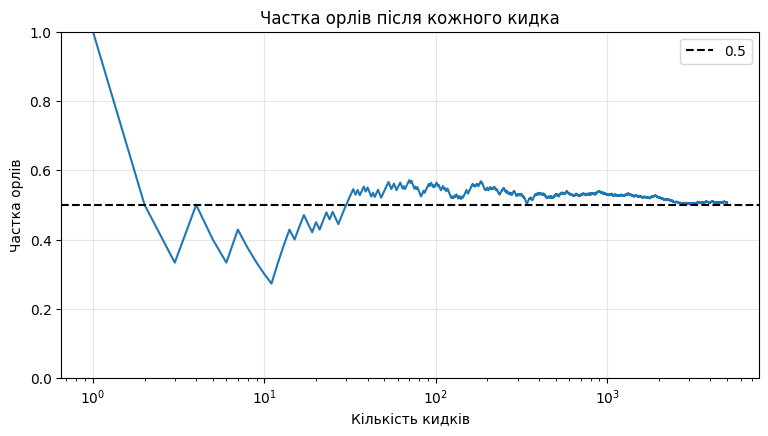

In [20]:
plt.plot(np.arange(1, 5001), running)
plt.axhline(0.5, color='black', linestyle='--', label='0.5')
plt.xscale('log')
plt.ylim(0, 1)
plt.title('Частка орлів після кожного кидка')
plt.xlabel('Кількість кидків')
plt.ylabel('Частка орлів')
plt.legend()
plt.show()

### Завдання 3.3. «Переможець» A/B-тесту, якого немає

Варіанти A і B сайту **однакові**: в обох конверсія 10%. Змоделюйте 2000 «тестів» по 30 відвідувачів на варіант і знайдіть частку тестів, де B **здається кращим щонайменше на 20%** (`b > 1.2 * a`). Збережіть у `share_small`. Повторіть для 3000 відвідувачів на варіант → `share_big`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`gen.binomial(30, 0.10, size=2000)` — скільки з 30 відвідувачів купили, у кожному з 2000 тестів. Ділимо на 30 — отримуємо конверсію. Частку тестів, де виконується умова, рахує `.mean()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
a = gen.binomial(30, 0.10, size=2000) / 30
b = gen.binomial(30, 0.10, size=2000) / 30
share_small = (b > 1.2 * a).mean()
```

Для 3000 відвідувачів — те саме, тільки замість 30 пишемо 3000 (і в `binomial`, і в діленні).

</details>

In [21]:
gen = np.random.default_rng(2)

a = gen.binomial(30, 0.10, size=2000) / 30
b = gen.binomial(30, 0.10, size=2000) / 30
share_small = (b > 1.2 * a).mean()

a_big = gen.binomial(3000, 0.10, size=2000) / 3000
b_big = gen.binomial(3000, 0.10, size=2000) / 3000
share_big = (b_big > 1.2 * a_big).mean()

print(f'30 відвідувачів:   B «краще» на 20%+ у {share_small:.1%} тестів')
print(f'3000 відвідувачів: B «краще» на 20%+ у {share_big:.1%} тестів')

30 відвідувачів:   B «краще» на 20%+ у 41.0% тестів
3000 відвідувачів: B «краще» на 20%+ у 1.0% тестів


In [ ]:
check('3.3', share_small, share_big)

**✍️ Менеджер провів тест на 30 відвідувачах на варіант і каже: «B кращий на 25%, запускаємо!». Що ви йому відповісте?**

*Ваша відповідь:* _на 30 відвідувачах "перевага 25%" - це різниця в одну-дві конверсії, тобто шум. Симуляція показує: коли варіанти однакові, B "виграє" 20%+ у 41% тестів при n = 30 і лише в 1% при n = 3000._

### Завдання 3.4. Середнє на кубику ⭐ *бонус*

Змоделюйте 10 000 кидків кубика й порахуйте середнє значення. Згідно з ЗВЧ воно має бути близько 3.5 (це середнє чисел 1, 2, 3, 4, 5, 6). Збережіть у `die_mean`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`gen.integers(1, 7, size=10_000)` — 10 000 чисел від 1 до 6. Далі — `.mean()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
die_mean = gen.integers(1, 7, size=10_000).mean()
```

</details>

In [22]:
gen = np.random.default_rng(3)
die_mean = gen.integers(1, 7, size=10000).mean()
print(f'Середнє: {die_mean:.3f} (теорія: 3.5)')

Середнє: 3.488 (теорія: 3.5)


In [ ]:
check('3.4', die_mean)

---

## Блок 4. Центральна гранична теорема

**Нагадування:** якщо багато разів брати вибірки розміру n і рахувати їхні середні, то розподіл цих середніх:
- має центр у μ;
- має розкид $SE = \dfrac{\sigma}{\sqrt{n}}$;
- наближається до нормального при великому n, **навіть якщо самі дані скошені**.

Працюємо знову з `app['session_min']`.

### Завдання 4.1. Форма генеральної сукупності

Побудуйте гістограму `session_min` (60 інтервалів) і порахуйте асиметрію. Збережіть асиметрію в `app_skew`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`plt.hist(дані, bins=60)` і `.skew()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
app_skew = app['session_min'].skew()
plt.hist(app['session_min'], bins=60)
plt.show()
```

</details>

Асиметрія: 1.80


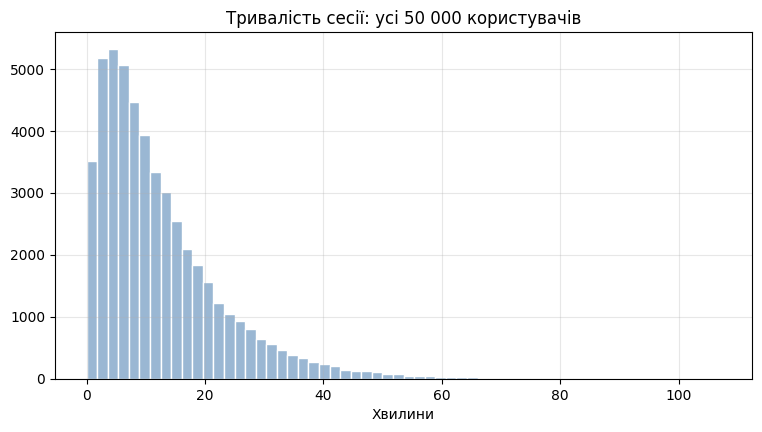

In [23]:
app_skew = app['session_min'].skew()
print(f'Асиметрія: {app_skew:.2f}')

plt.hist(app['session_min'], bins=60, color='#9ab7d3', edgecolor='white')
plt.title('Тривалість сесії: усі 50 000 користувачів')
plt.xlabel('Хвилини')
plt.show()

In [ ]:
check('4.1', app_skew)

### Завдання 4.2. 2000 вибіркових середніх

Візьміть 2000 вибірок по 40 користувачів (`random_state=i`, i від 0 до 1999) і збережіть їхні середні у список `means40`. Порахуйте середнє цих середніх (`mean_of_means`) і їхнє стандартне відхилення (`std_of_means`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Використайте такий самий list comprehension, як у завданні 2.4. Потім `np.mean(means40)` і `np.std(means40)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
means40 = [app['session_min'].sample(40, random_state=i).mean() for i in range(2000)]
mean_of_means = np.mean(means40)
std_of_means = np.std(means40)
```

Клітинка може виконуватись кілька секунд, це нормально.

</details>

In [24]:
means40 = [app['session_min'].sample(40, random_state=i).mean() for i in range(2000)]

mean_of_means = np.mean(means40)
std_of_means = np.std(means40)
print(f'Середнє з середніх: {mean_of_means:.2f}   (μ = {mu_app:.2f})')
print(f'Розкид середніх:    {std_of_means:.2f}')

Середнє з середніх: 12.50   (μ = 12.51)
Розкид середніх:    1.71


In [ ]:
check('4.2', mean_of_means, std_of_means)

### Завдання 4.3. Перевірка формули σ / √n

Порахуйте стандартну похибку за формулою `SE = σ / √40`, де σ — стандартне відхилення `session_min` у всій сукупності. Збережіть у `se_formula` і порівняйте з `std_of_means`.

<details>
<summary><b>💡 Підказка 1</b></summary>

σ — це `app['session_min'].std()`, корінь — `np.sqrt(40)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
sigma_app = app['session_min'].std()
se_formula = sigma_app / np.sqrt(40)
```

</details>

In [25]:
sigma_app = app['session_min'].std()
se_formula = sigma_app / np.sqrt(40)
print(f'σ = {sigma_app:.2f}')
print(f'Формула σ/√n: {se_formula:.2f} | Факт: {std_of_means:.2f}')

σ = 10.74
Формула σ/√n: 1.70 | Факт: 1.71


In [ ]:
check('4.3', se_formula)

### Завдання 4.4. n = 2 проти n = 40

Зробіть ще 2000 вибірок, але по **2** користувачі (`means2`). Порахуйте асиметрію `means2` і `means40` функцією `stats.skew` (`skew_2`, `skew_40`) і побудуйте дві гістограми поруч.

<details>
<summary><b>💡 Підказка 1</b></summary>

Для `means2` скопіюйте рядок із 4.2 і замініть 40 на 2. Асиметрію списку рахує `stats.skew(список)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
means2 = [app['session_min'].sample(2, random_state=i).mean() for i in range(2000)]
skew_2 = stats.skew(means2)
skew_40 = stats.skew(means40)
```

</details>

Асиметрія: дані = 1.80 | n=2: 1.34 | n=40: 0.24


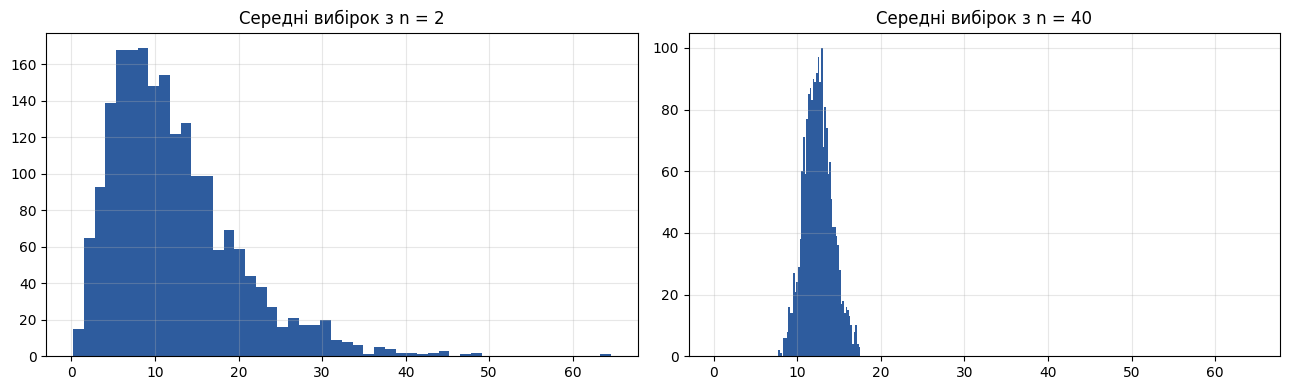

In [26]:
means2 = [app['session_min'].sample(2, random_state=i).mean() for i in range(2000)]
skew_2 = stats.skew(means2)
skew_40 = stats.skew(means40)
print(f'Асиметрія: дані = {app_skew:.2f} | n=2: {skew_2:.2f} | n=40: {skew_40:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
axes[0].hist(means2, bins=50, color='#2E5C9E')
axes[0].set_title('Середні вибірок з n = 2')
axes[1].hist(means40, bins=50, color='#2E5C9E')
axes[1].set_title('Середні вибірок з n = 40')
plt.tight_layout()
plt.show()

In [ ]:
check('4.4', skew_2, skew_40)

**✍️ Як змінюються форма і ширина розподілу середніх, коли n зростає з 2 до 40? Як це пов'язано з ЦГТ?**

*Ваша відповідь:* _форма стає симетричною (асиметрія падає з 1.34 до 0.24, тобто як skew_даних/√n), а ширина стискається приблизно вчетверо (як σ/√n, √20 ~ 4.5). Це і є ЦГТ: має центр у μ; має розкид σ/√n; наближається до нормального при великому n, навіть якщо самі дані скошені._

### Завдання 4.5. Скільки потрібно даних? ⭐ *бонус*

Яку мінімальну вибірку треба взяти, щоб стандартна похибка середнього була не більше **0.5 хв**? Розв'яжіть `σ / √n ≤ 0.5` відносно n і округліть угору. Збережіть у `n_needed`.

<details>
<summary><b>💡 Підказка 1</b></summary>

З формули SE = σ / √n виходить √n = σ / SE, тобто n = (σ / SE)². Округлення вгору — `np.ceil(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
n_needed = int(np.ceil((sigma_app / 0.5) ** 2))
```

</details>

In [27]:
n_needed = int(np.ceil((sigma_app / 0.5) ** 2))
print(f'Потрібно щонайменше {n_needed} користувачів')

Потрібно щонайменше 462 користувачів


In [ ]:
check('4.5', n_needed)

---

## Блок 5. Діаграма розсіювання і коваріація

Тепер працюємо з таблицею `students` — 800 студентів онлайн-школи.

| Колонка | Що означає |
|---|---|
| `plan` | тариф: Базовий або Преміум |
| `age` | вік |
| `hours_watched` | скільки годин відео переглянув |
| `tasks_done` | скільки домашніх завдань здав |
| `forum_posts` | скільки повідомлень написав на форумі |
| `support_tickets` | скільки разів звертався в підтримку |
| `weekly_load_h` | скільки годин на тиждень запланував на навчання |
| `satisfaction` | задоволеність курсом, 1–10 |
| `final_score` | бал за фінальний іспит, 0–100 |
| `passed` | склав іспит (бал ≥ 60) |

**Нагадування:**
- Діаграма розсіювання: `plt.scatter(x, y)`.
- Коваріація: $\text{cov}(x, y) = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{n-1}$. Знак показує напрям зв'язку, а величина залежить від одиниць виміру.
- У pandas: `df['a'].cov(df['b'])`.

### Завдання 5.1. Години відео і бал

Побудуйте діаграму розсіювання: по X — `hours_watched`, по Y — `final_score`. Підпишіть осі.

<details>
<summary><b>💡 Підказка 1</b></summary>

`plt.scatter(x, y, alpha=0.5)`. Параметр `alpha` робить точки напівпрозорими, щоб було видно, де їх багато.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
plt.scatter(students['hours_watched'], students['final_score'], alpha=0.5)
plt.xlabel('Годин відео')
plt.ylabel('Бал')
plt.show()
```

</details>

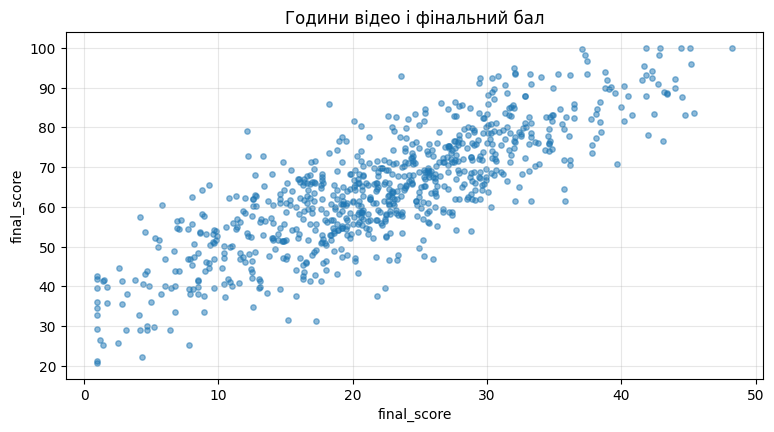

In [28]:
plt.scatter(students['hours_watched'], students['final_score'], alpha=0.5, s=15)
plt.title('Години відео і фінальний бал')
plt.xlabel('final_score')
plt.ylabel('final_score')
plt.show()

**✍️ Опишіть зв'язок: напрям, форма (пряма чи крива), сила (тісно чи «хмарою»), чи є викиди.**

*Ваша відповідь:* _Напрям - додатний; Форма - лінійна; Сила - помірно сильна, але не лінія, а хмара; Викиди - є, поодинокі, в обидва боки_

### Завдання 5.2. Чотири діаграми одразу

Побудуйте 4 діаграми розсіювання на одному малюнку (2 × 2): `final_score` по Y проти `tasks_done`, `forum_posts`, `age`, `support_tickets` по X.

<details>
<summary><b>💡 Підказка 1</b></summary>

`fig, axes = plt.subplots(2, 2, figsize=(12, 8))` створює 4 графіки. `axes.flat` дозволяє пройтися по них циклом разом зі списком колонок через `zip`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
cols = ['tasks_done', 'forum_posts', 'age', 'support_tickets']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cols):
    ax.scatter(students[col], students['final_score'], alpha=0.4, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel('final_score')
plt.tight_layout()
plt.show()
```

</details>

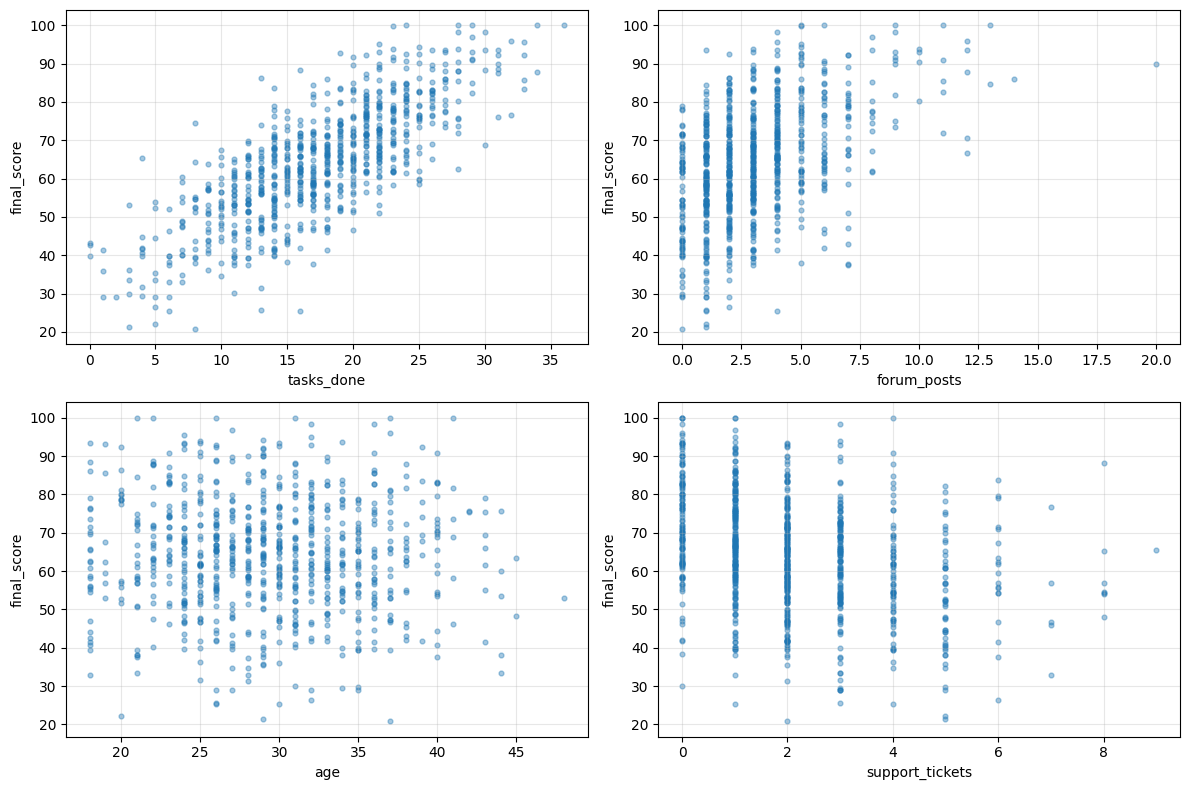

In [29]:
cols = ['tasks_done', 'forum_posts', 'age', 'support_tickets']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cols):
    ax.scatter(students[col], students['final_score'], alpha=0.4, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel('final_score')
plt.tight_layout()
plt.show()

**✍️ Для кожної з 4 змінних напишіть: зв'язок з балом позитивний, негативний чи його немає?**

*Ваша відповідь:* _tasks_done - сильний позитивний, age - зв'язку немає, forum_posts - слабкий позитивний, support_tickets - слабкий негативний._

### Завдання 5.3. Коваріація вручну

Для 6 студентів зі списків нижче порахуйте коваріацію між годинами і балом **вручну** за формулою. Збережіть у `cov_manual` і перевірте через `np.cov`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Кроки: відхилення x від середнього, відхилення y від середнього, перемножити попарно, скласти, поділити на n − 1.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
dx = x - x.mean()
dy = y - y.mean()
cov_manual = (dx * dy).sum() / (len(x) - 1)
```

`np.cov(x, y)` повертає матрицю 2×2, коваріація між x та y — елемент `[0, 1]`.

</details>

In [30]:
x = np.array([5, 10, 15, 20, 25, 30])      # години
y = np.array([45, 52, 60, 58, 70, 78])     # бал

dx = x - x.mean()
dy = y - y.mean()
print(pd.DataFrame({'x': x, 'y': y, 'dx': dx, 'dy': dy, 'dx·dy': dx * dy}))

cov_manual = (dx * dy).sum() / (len(x) - 1)
print(f'Вручну: {cov_manual:.1f} | np.cov: {np.cov(x, y)[0, 1]:.1f}')

    x   y      dx      dy   dx·dy
0   5  45 -12.500 -15.500 193.750
1  10  52  -7.500  -8.500  63.750
2  15  60  -2.500  -0.500   1.250
3  20  58   2.500  -2.500  -6.250
4  25  70   7.500   9.500  71.250
5  30  78  12.500  17.500 218.750
Вручну: 108.5 | np.cov: 108.5


In [ ]:
check('5.3', cov_manual)

### Завдання 5.4. Години чи хвилини?

Порахуйте коваріацію між `hours_watched` і `final_score` (`cov_h`). Потім переведіть години у **хвилини** (× 60) і порахуйте коваріацію ще раз (`cov_min`). Зробіть те саме для кореляції (`.corr`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Множення колонки на 60 дає нову колонку в хвилинах: `students['hours_watched'] * 60`. Потім викликаємо `.cov(...)` або `.corr(...)` з `students['final_score']`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
cov_h = students['hours_watched'].cov(students['final_score'])
cov_min = (students['hours_watched'] * 60).cov(students['final_score'])
```

</details>

In [31]:
cov_h = students['hours_watched'].cov(students['final_score'])
cov_min = (students['hours_watched'] * 60).cov(students['final_score'])
r_h = students['hours_watched'].corr(students['final_score'])
r_min = (students['hours_watched'] * 60).corr(students['final_score'])

print(f'Години:  коваріація = {cov_h:8.1f} | кореляція = {r_h:.3f}')
print(f'Хвилини: коваріація = {cov_min:8.1f} | кореляція = {r_min:.3f}')

Години:  коваріація =    115.4 | кореляція = 0.822
Хвилини: коваріація =   6922.8 | кореляція = 0.822


In [ ]:
check('5.4', cov_h, cov_min)

**✍️ Чому коваріацію незручно використовувати, щоб порівнювати силу зв'язків?**

*Ваша відповідь:* _Бо вона не має власної шкали - вона міряється в одиницях добутку обох змінних і разом з ними змінює масштаб_

---

## Блок 6. Коефіцієнт кореляції Пірсона

**Нагадування:**
$$r = \frac{\text{cov}(x, y)}{s_x \cdot s_y}$$

- r від −1 до +1; знак — напрям, модуль — сила **лінійного** зв'язку.
- Орієнтовно: |r| < 0.1 — немає; 0.1–0.3 — слабкий; 0.3–0.5 — помірний; 0.5–0.7 — помітний; > 0.7 — сильний.
- У pandas: `df['a'].corr(df['b'])` або `df.corr()` для всієї таблиці.
- ⚠️ Пірсон не бачить нелінійних зв'язків і чутливий до викидів.

### Завдання 6.1. Кореляція годин і балу

Порахуйте кореляцію Пірсона між `hours_watched` і `final_score`. Збережіть у `r_hours`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Метод `.corr()` для однієї колонки з іншою.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
r_hours = students['hours_watched'].corr(students['final_score'])
```

</details>

In [32]:
r_hours = students['hours_watched'].corr(students['final_score'])
print(f'r = {r_hours:.3f}')

r = 0.822


In [ ]:
check('6.1', r_hours)

### Завдання 6.2. Кореляція за формулою

Порахуйте ту саму кореляцію **за формулою**: коваріація ÷ (стандартне відхилення x × стандартне відхилення y). Збережіть у `r_manual`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Вам знадобляться `.cov(...)` і два `.std()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
x, y = students['hours_watched'], students['final_score']
r_manual = x.cov(y) / (x.std() * y.std())
```

</details>

In [33]:
x, y = students['hours_watched'], students['final_score']
r_manual = x.cov(y) / (x.std() * y.std())
print(f'За формулою: {r_manual:.3f} | .corr(): {r_hours:.3f}')

За формулою: 0.822 | .corr(): 0.822


In [ ]:
check('6.2', r_manual)

### Завдання 6.3. Що найсильніше пов'язане з балом?

Порахуйте кореляцію `final_score` з кожною числовою колонкою зі списку `num_cols`. Відсортуйте від найменшої до найбільшої. Збережіть назву колонки з **найсильнішим позитивним** зв'язком у `top_feature`, а колонки з кореляцією **найближчою до нуля** — у `weakest_feature`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`students[num_cols].corr()` дає всю матрицю. Колонка `['final_score']` — кореляції з балом. Приберіть сам `final_score` через `.drop('final_score')`. Назву з найбільшим значенням дає `.idxmax()`; найближче до нуля — `.abs().idxmin()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
corr_with_score = students[num_cols].corr()['final_score'].drop('final_score').sort_values()
top_feature = corr_with_score.idxmax()
weakest_feature = corr_with_score.abs().idxmin()
```

</details>

In [36]:
num_cols = ['age', 'hours_watched', 'tasks_done', 'forum_posts',
            'support_tickets', 'weekly_load_h', 'satisfaction', 'final_score']

corr_with_score = students[num_cols].corr()['final_score'].drop('final_score').sort_values()
print(corr_with_score.round(2))

top_feature = corr_with_score.idxmax()
weakest_feature = corr_with_score.abs().idxmin()
print('Найсильніший позитивний зв\'язок:', top_feature)
print('Найслабший зв\'язок:', weakest_feature)

support_tickets   -0.320
satisfaction      -0.030
age               -0.030
weekly_load_h      0.040
forum_posts        0.470
tasks_done         0.770
hours_watched      0.820
Name: final_score, dtype: float64
Найсильніший позитивний зв'язок: hours_watched
Найслабший зв'язок: age


In [ ]:
check('6.3', top_feature, weakest_feature)

### Завдання 6.4. Теплова карта кореляцій

Побудуйте теплову карту кореляційної матриці `students[num_cols]` з підписаними значеннями.

<details>
<summary><b>💡 Підказка 1</b></summary>

`plt.imshow(матриця, cmap='RdBu_r', vmin=-1, vmax=1)` малює кольорову сітку. Підписи осей — `plt.xticks`/`plt.yticks`, числа в клітинках — `plt.text` у подвійному циклі.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Заготовка вже майже повна: вам треба лише вказати матрицю і межі кольорової шкали від −1 до 1.

</details>

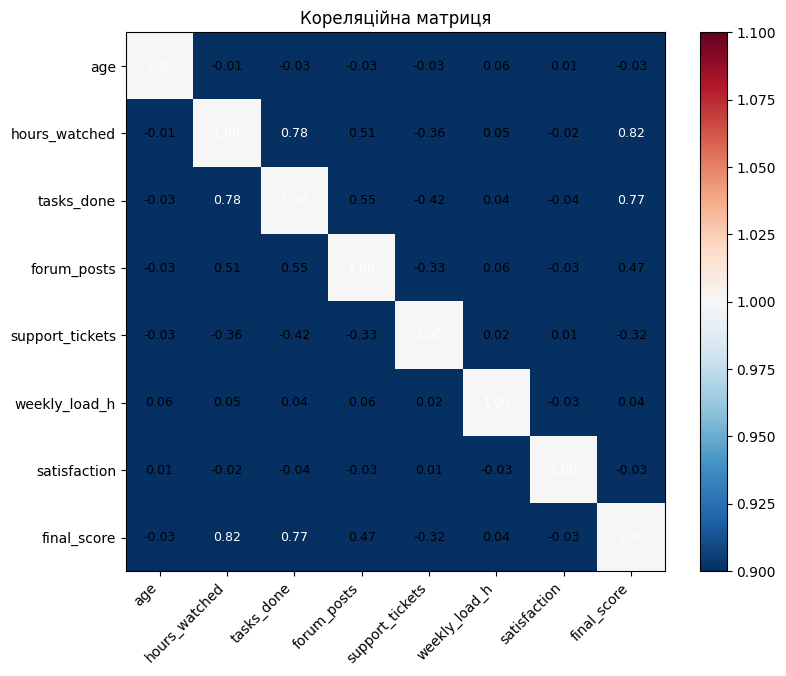

In [37]:
corr = students[num_cols].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap='RdBu_r', vmin=1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9,
                 color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
plt.colorbar()
plt.grid(False)
plt.title('Кореляційна матриця')
plt.show()

### Завдання 6.5. Навантаження і задоволеність: пастка нелінійності

Порахуйте кореляцію між `weekly_load_h` і `satisfaction` (`r_load`) і побудуйте діаграму розсіювання.

<details>
<summary><b>💡 Підказка 1</b></summary>

Як у 6.1 — `.corr()`, і як у 5.1 — `plt.scatter`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
r_load = students['weekly_load_h'].corr(students['satisfaction'])
plt.scatter(students['weekly_load_h'], students['satisfaction'], alpha=0.5)
plt.show()
```

</details>

r = -0.029


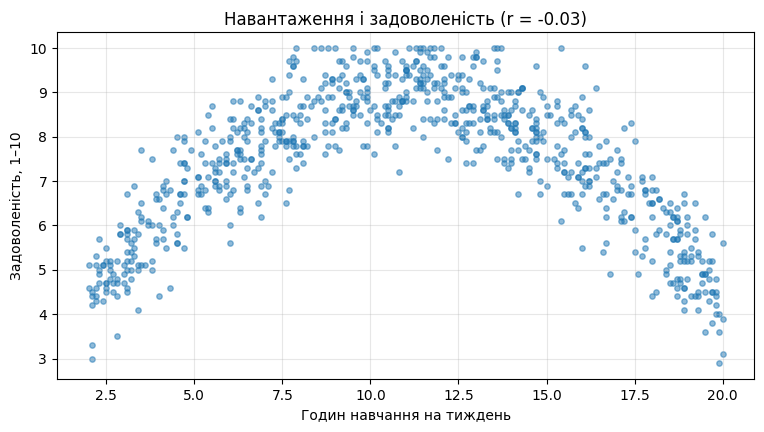

In [38]:
r_load = students['weekly_load_h'].corr(students['satisfaction'])
print(f'r = {r_load:.3f}')

plt.scatter(students['weekly_load_h'], students['satisfaction'], alpha=0.5, s=15)
plt.title(f'Навантаження і задоволеність (r = {r_load:.2f})')
plt.xlabel('Годин навчання на тиждень')
plt.ylabel('Задоволеність, 1–10')
plt.show()

In [ ]:
check('6.5', r_load)

**✍️ Кореляція майже нульова. Чи означає це, що задоволеність не залежить від навантаження? Що показує графік?**

*Ваша відповідь:* _Ні, залежність тут є. Пірсонова кореляція вміє бачити лише лінійну складову, а тут графік нелінійний - перевернута U_

### Завдання 6.6. Один викид

У списках нижче — дані 15 студентів, між якими зв'язку немає. Порахуйте кореляцію (`r_before`). Потім додайте **одного** студента-відмінника з x = 40, y = 70 і порахуйте ще раз (`r_after`). Додатково порахуйте кореляцію Спірмена після додавання (`method='spearman'`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Додати елемент у кінець масиву: `np.append(масив, значення)`. Кореляція двох масивів: `np.corrcoef(a, b)[0, 1]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
r_before = np.corrcoef(x_small, y_small)[0, 1]
x_out = np.append(x_small, 40)
y_out = np.append(y_small, 70)
r_after = np.corrcoef(x_out, y_out)[0, 1]
r_spear = pd.Series(x_out).corr(pd.Series(y_out), method='spearman')
```

</details>

In [40]:
x_small = np.array([12, 15, 11, 18, 14, 16, 13, 17, 15, 12, 19, 14, 16, 13, 18])
y_small = np.array([28, 29, 33, 31, 25, 34, 31, 28, 32, 30, 26, 27, 27, 30, 35])

r_before = np.corrcoef(x_small, y_small)[0, 1]

x_out = np.append(x_small, 40)
y_out = np.append(y_small, 70)
r_after = np.corrcoef(x_out, y_out)[0, 1]
r_spear = pd.Series(x_out).corr(pd.Series(y_out), method='spearman')

print(f'Без викиду: r = {r_before:.2f}')
print(f'З викидом:  r = {r_after:.2f}  | Спірмен = {r_spear:.2f}')

Без викиду: r = -0.02
З викидом:  r = 0.90  | Спірмен = 0.14


In [ ]:
check('6.6', r_before, r_after)

**✍️ Що зробив один студент з кореляцією Пірсона? Чому Спірмен змінився менше?**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

---

## Блок 7. Кореляція ≠ причинність

**Нагадування.** Якщо A і B корелюють, можливі пояснення:
- **A → B** — причинність;
- **B → A** — зворотна причинність;
- **A ← C → B** — третя змінна (конфаундер), яка впливає на обидві;
- **випадковий збіг**.

Причинність надійно доводять **експериментом** (A/B-тестом) з випадковим розподілом на групи.

Таблиця `city` — щоденні дані міста за 2 роки: `rain_mm` (опади, мм), `umbrellas` (продано парасольок), `accidents` (кількість ДТП).

### Завдання 7.1. Парасольки і ДТП

Порахуйте кореляцію між `umbrellas` і `accidents`. Збережіть у `r_ua`. Побудуйте діаграму розсіювання, розфарбувавши точки за `rain_mm`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Колір точок задається параметром `c=...` у `plt.scatter`, а шкалу кольорів додає `plt.colorbar()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
r_ua = city['umbrellas'].corr(city['accidents'])
plt.scatter(city['umbrellas'], city['accidents'], c=city['rain_mm'], cmap='Blues')
plt.colorbar(label='Опади, мм')
plt.show()
```

</details>

r = 0.56


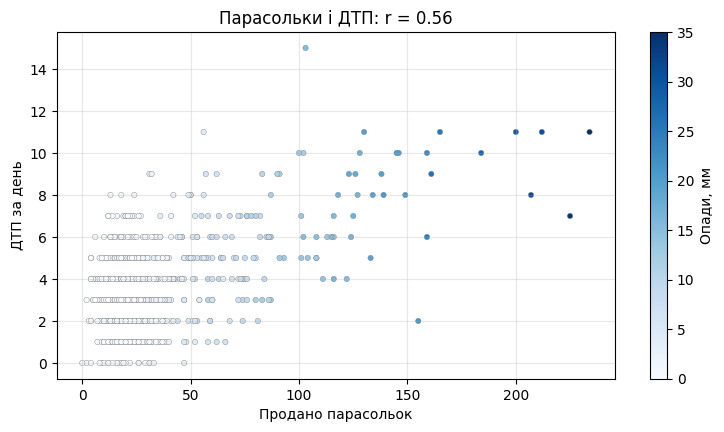

In [41]:
r_ua = city['umbrellas'].corr(city['accidents'])
print(f'r = {r_ua:.2f}')

plt.scatter(city['umbrellas'], city['accidents'], c=city['rain_mm'], cmap='Blues', s=15, edgecolor='gray', linewidth=0.3)
plt.colorbar(label='Опади, мм')
plt.title(f'Парасольки і ДТП: r = {r_ua:.2f}')
plt.xlabel('Продано парасольок')
plt.ylabel('ДТП за день')
plt.show()

In [ ]:
check('7.1', r_ua)

**✍️ Чи варто мерії заборонити продаж парасольок, щоб зменшити кількість ДТП? Поясніть, що насправді відбувається.**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

### Завдання 7.2. Контроль третьої змінної

Розбийте дні на групи за опадами: «без дощу» (0 мм), «слабкий» (до 3 мм), «помірний» (3–10 мм), «сильний» (понад 10 мм). Порахуйте кореляцію парасольок і ДТП **всередині кожної групи**. Збережіть кореляцію в групі «без дощу» в `r_dry`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`pd.cut` ділить числа на інтервали за межами `bins` і дає їм назви `labels`. Потім `groupby` за новою колонкою і `.apply(...)` з функцією, яка рахує кореляцію всередині групи.

Коли подивитеся на результат, зверніть увагу: наскільки різними можуть бути опади всередині групи «сильний» (від 10 до 35 мм)?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
city['rain_group'] = pd.cut(city['rain_mm'], bins=[-0.1, 0.05, 3, 10, 200],
                            labels=['без дощу', 'слабкий', 'помірний', 'сильний'])
within = city.groupby('rain_group', observed=True).apply(lambda g: g['umbrellas'].corr(g['accidents']))
r_dry = within['без дощу']
```

</details>

In [43]:
city['rain_group'] = pd.cut(city['rain_mm'], bins=[-0.1, 0.05, 3, 10, 200],
                            labels=['без дощу', 'слабкий', 'помірний', 'сильний'])
print(city['rain_group'].value_counts())

within = city.groupby('rain_group', observed=True).apply(lambda g: g['umbrellas'].corr(g['accidents']))
print('\nКореляція всередині груп:')
print(within.round(2))

r_dry = within['без дощу']

rain_group
без дощу    411
слабкий     143
помірний    115
сильний      61
Name: count, dtype: int64

Кореляція всередині груп:
rain_group
без дощу   -0.030
слабкий     0.120
помірний    0.140
сильний     0.440
dtype: float64


In [ ]:
check('7.2', r_dry)

**✍️ Що стається з кореляцією, коли ми порівнюємо дні зі схожою погодою? Про що це свідчить?**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

### Завдання 7.3. Чи підвищує Преміум-тариф бал?

Порахуйте середній `final_score` для кожного тарифу і різницю «Преміум − Базовий». Збережіть різницю в `diff_plan`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`groupby('plan')['final_score'].mean()` дає середнє для кожного тарифу. Різниця — просто віднімання двох значень за назвами.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
by_plan_score = students.groupby('plan')['final_score'].mean()
diff_plan = by_plan_score['Преміум'] - by_plan_score['Базовий']
```

</details>

In [45]:
by_plan_score = students.groupby('plan')['final_score'].mean()
print(by_plan_score.round(1))

diff_plan = by_plan_score['Преміум'] - by_plan_score['Базовий']
print(f'Різниця: {diff_plan:+.1f} бала на користь Преміуму')

plan
Базовий   59.800
Преміум   74.200
Name: final_score, dtype: float64
Різниця: +14.4 бала на користь Преміуму


In [ ]:
check('7.3', diff_plan)

**✍️ Відділ маркетингу хоче написати в рекламі: «Преміум-тариф підвищує бал на 14 пунктів!». Чи можна так стверджувати? Яка може бути третя змінна?**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

### Завдання 7.4. Порівнюємо схожих студентів ⭐ *бонус*

Розбийте студентів на 4 рівні групи за `hours_watched` і порівняйте середній бал тарифів **всередині кожної групи**. Збережіть середню різницю «Преміум − Базовий» по групах у `avg_within_diff`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`pd.qcut(колонка, 4)` ділить на 4 групи з однаковою кількістю студентів. Групування за двома колонками + `.unstack()` розгортає тарифи в окремі колонки.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
students['hours_group'] = pd.qcut(students['hours_watched'], 4)
pivot = students.groupby(['hours_group', 'plan'], observed=True)['final_score'].mean().unstack()
pivot['різниця'] = pivot['Преміум'] - pivot['Базовий']
avg_within_diff = pivot['різниця'].mean()
```

</details>

In [46]:
students['hours_group'] = pd.qcut(students['hours_watched'], 4)
pivot = students.groupby(['hours_group', 'plan'], observed=True)['final_score'].mean().unstack()
pivot['різниця'] = pivot['Преміум'] - pivot['Базовий']
print(pivot.round(1))

avg_within_diff = pivot['різниця'].mean()
print(f'Загальна різниця: {diff_plan:+.1f} | Середня різниця всередині груп: {avg_within_diff:+.1f}')

plan            Базовий  Преміум  різниця
hours_group                              
(0.999, 16.3]    48.700   53.400    4.700
(16.3, 22.4]     59.600   62.500    2.900
(22.4, 28.725]   67.500   69.200    1.700
(28.725, 48.2]   77.100   81.300    4.200
Загальна різниця: +14.4 | Середня різниця всередині груп: +3.4


In [ ]:
check('7.4', avg_within_diff)

**✍️ Як змінилась різниця, коли ми порівняли студентів зі схожою кількістю годин? Що це означає?**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

### Завдання 7.5. Що за зв'язок?

Для кожного твердження визначте найімовірніше пояснення: **причинність**, **зворотна причинність**, **третя змінна** або **випадковість**. Коротко поясніть.

а) У магазинах, які частіше роблять знижки, менший середній чек.

б) Країни, де їдять більше шоколаду, мають більше нобелівських лауреатів на душу населення.

в) У відділеннях лікарні, де на зміні більше лікарів, більше пацієнтів у важкому стані.

г) У дні, коли продається більше сонцезахисного крему, більше заявок на ремонт кондиціонерів.

<details>
<summary><b>💡 Підказка 1</b></summary>

Для кожного випадку запитайте себе: що відбувається **раніше**? Чи є щось, що могло вплинути на **обидві** величини одночасно?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Підказки до складних пунктів: б) подумайте, у яких країнах люди можуть дозволити собі багато шоколаду і великі витрати на науку; в) чому лікарня ставить на зміну більше лікарів?

</details>

In [ ]:
# Це текстове завдання: відповідь напишіть у клітинці нижче

**✍️ а) … б) … в) … г) …**

*Ваша відповідь:* _а) Причинність (пряма, механічна). Знижка безпосередньо зменшує суму, яку платить покупець, — це той самий чек, тільки менший.
б) Третя змінна — добробут країни. Багаті країни одночасно споживають більше дорогих продуктів (шоколад — серед них) і мають розвинену науку, фінансування досліджень.
в) Зворотна причинність. Не лікарі погіршують стан пацієнтів — навпаки, лікарні ставлять більше персоналу туди, де пацієнти важчі.
г) Третя змінна — спека. У гарячі дні люди і купують крем від сонця, і вмикають кондиціонери на повну, від чого ті частіше ламаються._

---

## Блок 8. Підсумкове завдання: міні-звіт

Керівник онлайн-школи питає: **«Що пов'язано з високим балом студентів і що нам робити?»**

### Завдання 8.1. Звіт для керівника

Використайте результати попередніх завдань (або порахуйте нові) і напишіть звіт з 4–6 речень простою мовою. У звіті має бути:

1. які показники найсильніше пов'язані з балом і наскільки (числа r);
2. які показники з балом не пов'язані;
3. що з цього **не можна** вважати доведеною причиною і чому;
4. одна порада, як перевірити причинний ефект (наприклад, експеримент).

<details>
<summary><b>💡 Підказка 1</b></summary>

Корисно ще раз вивести `corr_with_score` із завдання 6.3 і подивитися на теплову карту з 6.4.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Шаблон: «Найсильніше з балом пов'язані … (r = …) і … (r = …). Майже не пов'язані … . Але це кореляції, а не доведені причини: … . Щоб перевірити, чи справді … підвищує бал, варто …»

</details>

In [47]:
# За потреби — додаткові розрахунки
corr_with_score.sort_values(ascending=False).round(2)

,final_score
hours_watched,0.820
tasks_done,0.770
forum_posts,0.470
weekly_load_h,0.040
age,-0.030
satisfaction,-0.030
support_tickets,-0.320


**✍️ Звіт для керівника (4–6 речень):**

*Ваша відповідь:* _Найсильніше з фінальним балом пов'язані години перегляду відео (r = 0.82), виконані завдання (r = 0.77) і активність на форумі (r = 0.47), тоді як звернення в підтримку мають зворотний зв'язок (r = −0.32). Вік, тижневе навантаження та задоволеність із балом практично не пов'язані (|r| <= 0.04). Вважати це доведеною причиною не можна: найімовірніше, за зв'язком стоїть - мотивація чи вільний час, - бо мотивовані студенти і дивляться більше відео, і виконують більше завдань; а у випадку підтримки причинність радше зворотна: не звернення знижують бал, а студенти з труднощами частіше пишуть у підтримку. Щоб перевірити реальний ефект, пропоную A/B-експеримент: випадково поділити нових студентів на дві групи, одній надсилати нагадування про перегляд відео, і порівняти середні бали._

---
## 🎉 Готово!

Ви пройшли ймовірність, вибірки, закон великих чисел, центральну граничну теорему, коваріацію, кореляцію і різницю між кореляцією та причинністю.

**Перед здачею:** *Runtime → Restart and run all* (у Colab) — переконайтеся, що весь блокнот запускається зверху вниз без помилок.